In [3]:
!pip install -q mat73

In [6]:
import os

file_paths = []

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file.endswith(".mat"):
            file_path = os.path.join(root, file)
            print(file_path)
            file_paths.append(file_path)

/kaggle/input/datasets/weinanwangrutgers/pulsedb-balanced-training-and-testing/VitalDB_AAMI_Cal_Subset.mat
/kaggle/input/datasets/weinanwangrutgers/pulsedb-balanced-training-and-testing/VitalDB_Train_Subset.mat
/kaggle/input/datasets/weinanwangrutgers/pulsedb-balanced-training-and-testing/VitalDB_AAMI_Test_Subset.mat
/kaggle/input/datasets/weinanwangrutgers/pulsedb-balanced-training-and-testing/VitalDB_CalFree_Test_Subset.mat
/kaggle/input/datasets/weinanwangrutgers/pulsedb-balanced-training-and-testing/VitalDB_CalBased_Test_Subset.mat


In [7]:
import sys

sys.path.append("/kaggle/input/datasets/bosuacuoi/pulsedb-reader")

from reader import PulseDBReader

In [9]:
reader = PulseDBReader(file_paths[0])

all_segments = reader.read()

print("Tổng segment:", len(all_segments))
print("Tổng subject:", len(set(s.subject_id for s in all_segments)))

Tổng segment: 70212
Tổng subject: 116


In [11]:
from collections import defaultdict

by_subject = defaultdict(list)

for s in all_segments:
    if len(by_subject[s.subject_id]) < 10:
        by_subject[s.subject_id].append(s)

selected_segments = []

for subject_id in by_subject:
    if len(by_subject[subject_id]) == 10:
        selected_segments.extend(by_subject[subject_id])

    if len(selected_segments) >= 1000:
        break

selected_segments = selected_segments[:1000]

print("Số segment:", len(selected_segments))
print("Số subject:", len(set(s.subject_id for s in selected_segments)))

Số segment: 1000
Số subject: 100


In [12]:
s = selected_segments[0]

print("Subject ID:", s.subject_id)
print("Gender:", s.gender)
print("Age:", s.age)
print("Height:", s.height_cm)
print("Weight:", s.weight_kg)
print("BMI:", s.bmi_kg_m2)
print("SBP:", s.sbp)
print("DBP:", s.dbp)

print("ECG shape:", s.ecg.shape)
print("PPG shape:", s.ppg.shape)
print("ABP shape:", s.abp.shape)

In [14]:
ecg_lengths = [len(s.ecg) for s in selected_segments]
ppg_lengths = [len(s.ppg) for s in selected_segments]
abp_lengths = [len(s.abp) for s in selected_segments]

print("ECG:")
print("  Min:", min(ecg_lengths))
print("  Max:", max(ecg_lengths))

print("PPG:")
print("  Min:", min(ppg_lengths))
print("  Max:", max(ppg_lengths))

print("ABP:")
print("  Min:", min(abp_lengths))
print("  Max:", max(abp_lengths))

ECG:
  Min: 1250
  Max: 1250
PPG:
  Min: 1250
  Max: 1250
ABP:
  Min: 1250
  Max: 1250


In [15]:
import numpy as np

for name in ["ecg", "ppg", "abp"]:
    total_missing = sum(
        np.isnan(getattr(s, name)).sum()
        for s in selected_segments
    )

    print(f"{name.upper()} missing:", total_missing)


ECG missing: 0
PPG missing: 0
ABP missing: 0


In [17]:
import pandas as pd

metadata = pd.DataFrame([
    {
        "subject_id": s.subject_id,
        "gender": s.gender,
        "age": s.age,
        "height": s.height_cm,
        "weight": s.weight_kg,
        "bmi": s.bmi_kg_m2,
        "sbp": s.sbp,
        "dbp": s.dbp,
    }
    for s in selected_segments
])

print(metadata.isna().sum())

subject_id    0
gender        0
age           0
height        0
weight        0
bmi           0
sbp           0
dbp           0
dtype: int64


In [18]:
print("SBP:")
print(metadata["sbp"].describe())

print("\nDBP:")
print(metadata["dbp"].describe())

SBP:
count    1000.000000
mean      119.497255
std        22.724643
min        66.213052
25%       104.877491
50%       116.798145
75%       132.480969
max       265.552833
Name: sbp, dtype: float64

DBP:
count    1000.000000
mean       66.698252
std        15.370519
min        34.727826
25%        56.414356
50%        65.613712
75%        75.996677
max       258.483669
Name: dbp, dtype: float64


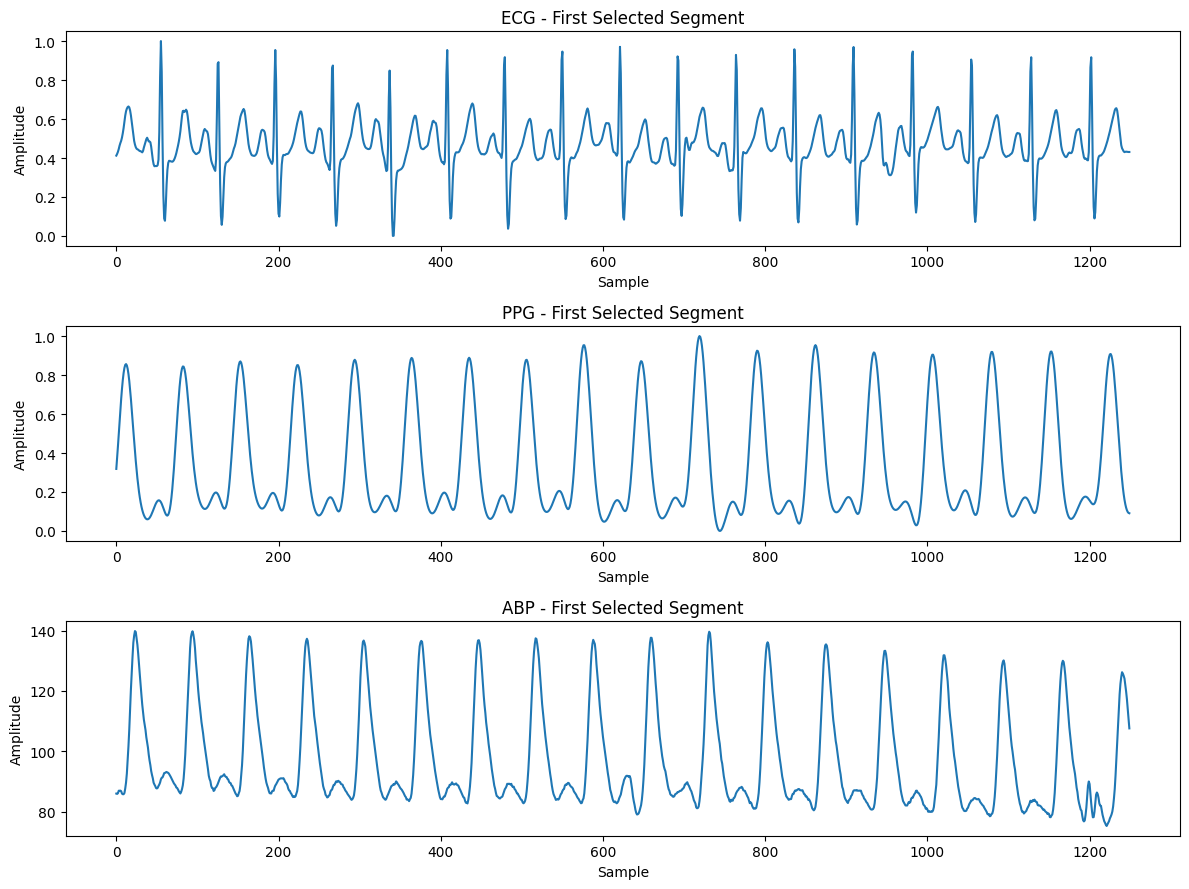

In [20]:
import matplotlib.pyplot as plt

s = selected_segments[0]

plt.figure(figsize=(12, 9))

# ECG
plt.subplot(3, 1, 1)
plt.plot(s.ecg)
plt.title("ECG - First Selected Segment")
plt.xlabel("Sample")
plt.ylabel("Amplitude")

# PPG
plt.subplot(3, 1, 2)
plt.plot(s.ppg)
plt.title("PPG - First Selected Segment")
plt.xlabel("Sample")
plt.ylabel("Amplitude")

# ABP
plt.subplot(3, 1, 3)
plt.plot(s.abp)
plt.title("ABP - First Selected Segment")
plt.xlabel("Sample")
plt.ylabel("Amplitude")

plt.tight_layout()
plt.show()

In [21]:
manifest = pd.DataFrame([
    {
        "sample_id": i,
        "subject_id": s.subject_id,
        "source": "VitalDB_AAMI_Cal_Subset.mat",
        "split": None,
        "sbp": s.sbp,
        "dbp": s.dbp,
    }
    for i, s in enumerate(selected_segments)
])

print(manifest.head())
print("\nSố dòng:", len(manifest))
print("Số subject:", manifest["subject_id"].nunique())

In [28]:
import random

seed = 72

subjects = sorted(manifest["subject_id"].unique())

random.seed(seed)
random.shuffle(subjects)

n = len(subjects)

n_train = int(n * 0.8)
n_val = int(n * 0.1)

train_subjects = subjects[:n_train]
val_subjects = subjects[n_train:n_train + n_val]
test_subjects = subjects[n_train + n_val:]

print("Train:", len(train_subjects))
print("Validation:", len(val_subjects))
print("Test:", len(test_subjects))

Train: 80
Validation: 10
Test: 10


In [29]:
def get_split(subject_id):
    if subject_id in train_subjects:
        return "train"
    elif subject_id in val_subjects:
        return "val"
    else:
        return "test"


manifest["split"] = manifest["subject_id"].apply(get_split)

print(manifest["split"].value_counts())

split
train    800
val      100
test     100
Name: count, dtype: int64


In [31]:
print(manifest[["sample_id", "subject_id", "split", "sbp", "dbp"]].to_string(index=False))

In [40]:
train_ids = set(manifest[manifest["split"] == "train"]["subject_id"])
val_ids = set(manifest[manifest["split"] == "val"]["subject_id"])
test_ids = set(manifest[manifest["split"] == "test"]["subject_id"])

print("Train ∩ Val:", train_ids & val_ids)
print("Train ∩ Test:", train_ids & test_ids)
print("Val ∩ Test:", val_ids & test_ids)

Train ∩ Val: set()
Train ∩ Test: set()
Val ∩ Test: set()


In [57]:
import hashlib
import numpy as np

def make_sample_hash(segment):
    h = hashlib.sha256()

    # Metadata
    h.update(str(segment.subject_id).encode())
    h.update(str(segment.gender).encode())
    h.update(str(segment.age).encode())
    h.update(str(segment.height_cm).encode())
    h.update(str(segment.weight_kg).encode())
    h.update(str(segment.bmi_kg_m2).encode())
    h.update(str(segment.sbp).encode())
    h.update(str(segment.dbp).encode())

    # Signals
    h.update(np.asarray(segment.ecg).tobytes())
    h.update(np.asarray(segment.ppg).tobytes())
    h.update(np.asarray(segment.abp).tobytes())

    return h.hexdigest()

In [70]:
manifest["sample_hash"] = [
    make_sample_hash(s)
    for s in selected_segments
]

In [68]:
hash_table = manifest[
    ["sample_id", "subject_id", "split", "sample_hash"]
].copy()

display(hash_table)
print("Số sample_id khác nhau:", hash_table["sample_id"].nunique())
print("Hash khác nhau:", hash_table["sample_hash"].nunique())

Số sample_id khác nhau: 1000
Hash khác nhau: 1000


In [63]:
bp_distribution = manifest.groupby("split")[["sbp", "dbp"]].agg(
    ["count", "mean", "std", "min", "max"]
)

print(bp_distribution)

        sbp                                                 dbp             \
      count        mean        std        min         max count       mean   
split                                                                        
test    100  111.927846  24.658896  72.902452  180.633523   100  61.075510   
train   800  120.444186  22.110805  66.213052  265.552833   800  67.008070   
val     100  119.491211  24.334931  83.428215  210.058996   100  69.842444   

                                         
             std        min         max  
split                                    
test   10.601142  42.793589   87.719028  
train  16.127087  34.727826  258.483669  
val    11.396174  48.683233   92.406697  


In [79]:
def validate_manifest(manifest):
    errors = []

    if manifest["sample_id"].duplicated().any():
        errors.append("Có sample_id bị trùng")

    if manifest["sample_hash"].duplicated().any():
        errors.append("Có sample_hash bị trùng")

    if manifest["subject_id"].isna().any():
        errors.append("Có subject_id bị thiếu")

    if manifest["split"].isna().any():
        errors.append("Có sample chưa được chia split")

    valid_splits = {"train", "val", "test"}

    if not set(manifest["split"].dropna()).issubset(valid_splits):
        errors.append("Có split không hợp lệ")

    subject_split_count = (
        manifest.groupby("subject_id")["split"]
        .nunique()
    )

    if (subject_split_count > 1).any():
        errors.append("Có subject xuất hiện ở nhiều split")

    if errors:
        print("Manifest KHÔNG hợp lệ:")
        for error in errors:
            print("-", error)
        return False

    print("Manifest hợp lệ")
    return True

In [80]:
validate_manifest(manifest)

Manifest hợp lệ


True

In [83]:
# =========================
# NEGATIVE TESTS
# =========================

# Test 1: Trùng sample_id
bad_manifest = manifest.copy()
bad_manifest.loc[1, "sample_id"] = bad_manifest.loc[0, "sample_id"]

print("TEST 1 - Duplicate sample_id")
validate_manifest(bad_manifest)


# Test 2: Subject xuất hiện ở 2 split
bad_manifest = manifest.copy()
test_subject = bad_manifest.loc[0, "subject_id"]

# Đổi split của 1 sample thuộc subject này
original_split = bad_manifest.loc[0, "split"]
new_split = "test" if original_split != "test" else "train"
bad_manifest.loc[0, "split"] = new_split

print("\nTEST 2 - Subject leakage")
validate_manifest(bad_manifest)


# Test 3: Thiếu subject_id
bad_manifest = manifest.copy()
bad_manifest.loc[0, "subject_id"] = None

print("\nTEST 3 - Missing subject_id")
validate_manifest(bad_manifest)


# Test 4: Thiếu split
bad_manifest = manifest.copy()
bad_manifest.loc[0, "split"] = None

print("\nTEST 4 - Missing split")
validate_manifest(bad_manifest)


# Test 5: Split không hợp lệ
bad_manifest = manifest.copy()
bad_manifest.loc[0, "split"] = "wrong_split"

print("\nTEST 5 - Invalid split")
validate_manifest(bad_manifest)

TEST 1 - Duplicate sample_id
Manifest KHÔNG hợp lệ:
- Có sample_id bị trùng

TEST 2 - Subject leakage
Manifest KHÔNG hợp lệ:
- Có subject xuất hiện ở nhiều split

TEST 3 - Missing subject_id
Manifest KHÔNG hợp lệ:
- Có subject_id bị thiếu

TEST 4 - Missing split
Manifest KHÔNG hợp lệ:
- Có sample chưa được chia split

TEST 5 - Invalid split
Manifest KHÔNG hợp lệ:
- Có split không hợp lệ
- Có subject xuất hiện ở nhiều split


False

In [84]:
import random

# Hàm chia subject
def make_split(subject_ids, seed=72):
    subjects = sorted(subject_ids)

    random.seed(seed)
    random.shuffle(subjects)

    n = len(subjects)
    n_train = int(n * 0.8)
    n_val = int(n * 0.1)

    train = subjects[:n_train]
    val = subjects[n_train:n_train + n_val]
    test = subjects[n_train + n_val:]

    return train, val, test


# Chạy lần 1
train_1, val_1, test_1 = make_split(
    manifest["subject_id"].unique(),
    seed=72
)

# Chạy lần 2 với đúng dữ liệu và seed
train_2, val_2, test_2 = make_split(
    manifest["subject_id"].unique(),
    seed=72
)


# So sánh
print("Train giống nhau:", train_1 == train_2)
print("Val giống nhau:", val_1 == val_2)
print("Test giống nhau:", test_1 == test_2)

print("\nKết quả:")
if train_1 == train_2 and val_1 == val_2 and test_1 == test_2:
    print("Reproducible: cùng input + cùng seed → cùng split")
else:
    print("Không reproducible")

Train giống nhau: True
Val giống nhau: True
Test giống nhau: True

Kết quả:
Reproducible: cùng input + cùng seed → cùng split


In [85]:
manifest.to_csv(
    "/kaggle/working/pulsedb_manifest_1000.csv",
    index=False
)

print("Đã lưu manifest:", "/kaggle/working/pulsedb_manifest_1000.csv")

Đã lưu manifest: /kaggle/working/pulsedb_manifest_1000.csv
